# 4. Gradient Boosting Regressor (better model)

**Better / extracurricular model.** Instead of one formula for every borrower, boosting builds a SUM of many
small regression trees, each one fitted to what the previous trees still get wrong:

    F_0(x)  = mean(y)                          start: the average rate for everyone
    r_i     = y_i - F_(m-1)(x_i)               residual = how wrong the ensemble still is
    h_m     = small tree fitted to (x_i, r_i)  on a random 80% of the rows
    F_m(x)  = F_(m-1)(x) + learning_rate * h_m(x)

For squared error the residual IS the negative gradient, so this is gradient descent in function space.
The trees can ask "fico < 700 AND revol.util > 60?", so interactions and curves are learned automatically.
`n_estimators`, `max_depth` and `learning_rate` are chosen by 3-fold CV on the train set only.

From-scratch code: `RegressionAlgorithms/BetterModel_GradientBoostingRegressor.py` (`GradientBoostingRegressorScratch`)

Charts: `Images/Regression/04_Gradient_Boosting_Regressor/` · tables: `Results/Regression/04_Gradient_Boosting_Regressor/`

## 1. Setup and data

In [1]:
# Setup: imports, data and the fixed 80/20 train/test split (seed 42)
import os
import sys

sys.path.insert(0, os.path.abspath(os.path.join("..", "..", "Common")))

import numpy as np
from project import SEED, Outputs, regression_data
from model_zoo import RegressionPipeline, check_settings
from report_regression import report_regressor
import itertools
import pandas as pd
import plots
from BetterModel_GradientBoostingRegressor import GradientBoostingRegressorScratch
from metrics import mse, permutation_importance, r2
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import KFold, cross_val_score

out = Outputs("Regression", "04_Gradient_Boosting_Regressor")
d = regression_data()
print(f"train {d.X_train.shape} | test {d.X_test.shape} | target int.rate | {len(d.feature_cols)} features")

train (7662, 20) | test (1916, 20) | target int.rate | 20 features


## 2. Model

In [2]:
# Model, step 1: choose the settings by 3-fold CV on the TRAIN set only
# (scikit-learn's GradientBoostingRegressor is a fast stand-in for this search)
best = None
for n_est, depth, lr in itertools.product([300, 600], [3, 4], [0.05, 0.1]):
    sk = GradientBoostingRegressor(
        n_estimators=n_est, max_depth=depth, learning_rate=lr, subsample=0.8, min_samples_leaf=5, random_state=SEED
    )
    score = cross_val_score(sk, d.X_train, d.y_train, cv=KFold(3, shuffle=True, random_state=SEED), scoring="r2").mean()
    print(f"  n_estimators={n_est:<4} max_depth={depth} learning_rate={lr:<5} -> CV R2 = {score:.4f}")
    if best is None or score > best[0]:
        best = (score, n_est, depth, lr)
gbr = {"n_estimators": best[1], "max_depth": best[2], "learning_rate": best[3]}
out.save_json("chosen_settings.json", gbr)  # the comparison notebook refits with these
print("chosen:", gbr, "subsample=0.8")

# Model, step 2: train the from-scratch booster with those settings (no scaling needed for trees)
model = RegressionPipeline(
    GradientBoostingRegressorScratch(
        gbr["n_estimators"], gbr["learning_rate"], gbr["max_depth"], subsample=0.8, random_state=SEED
    ),
    scale=False,
)
check_settings("4. Gradient Boosting (better)", model, gbr=gbr)
model.fit(d.X_train, d.y_train, d.feature_cols)

# verification: scikit-learn GradientBoostingRegressor with the same settings
sk = GradientBoostingRegressor(
    n_estimators=gbr["n_estimators"],
    max_depth=gbr["max_depth"],
    learning_rate=gbr["learning_rate"],
    subsample=0.8,
    min_samples_leaf=5,
    random_state=SEED,
).fit(d.X_train, d.y_train)
sk_r2 = sk.score(d.X_test, d.y_test)

  n_estimators=300  max_depth=3 learning_rate=0.05  -> CV R2 = 0.7565


  n_estimators=300  max_depth=3 learning_rate=0.1   -> CV R2 = 0.7590


  n_estimators=300  max_depth=4 learning_rate=0.05  -> CV R2 = 0.7611


  n_estimators=300  max_depth=4 learning_rate=0.1   -> CV R2 = 0.7585


  n_estimators=600  max_depth=3 learning_rate=0.05  -> CV R2 = 0.7601


  n_estimators=600  max_depth=3 learning_rate=0.1   -> CV R2 = 0.7581


  n_estimators=600  max_depth=4 learning_rate=0.05  -> CV R2 = 0.7617


  n_estimators=600  max_depth=4 learning_rate=0.1   -> CV R2 = 0.7545
chosen: {'n_estimators': 600, 'max_depth': 4, 'learning_rate': 0.05} subsample=0.8
settings match Common/model_zoo.py (11 values checked)


## 3. Results

Train loss (MSE)   0.000091
Test loss (MSE)    0.000165
Test RMSE          0.012860
Test MAE           0.009023
Test R2            0.759776
scikit-learn R2    0.757452
Difference         0.002325

scratch vs scikit-learn GradientBoostingRegressor (different random subsamples): R2 0.7598 vs 0.7575 (difference +0.0023)


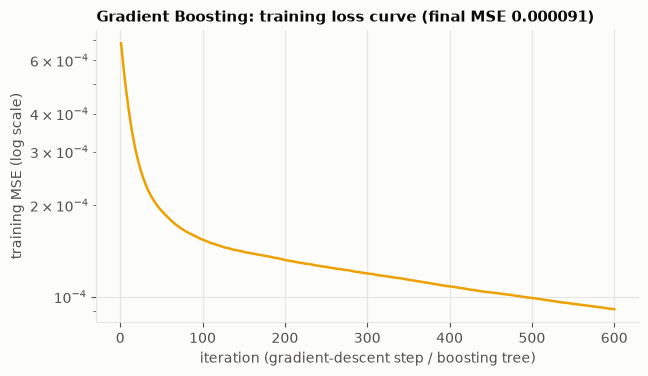

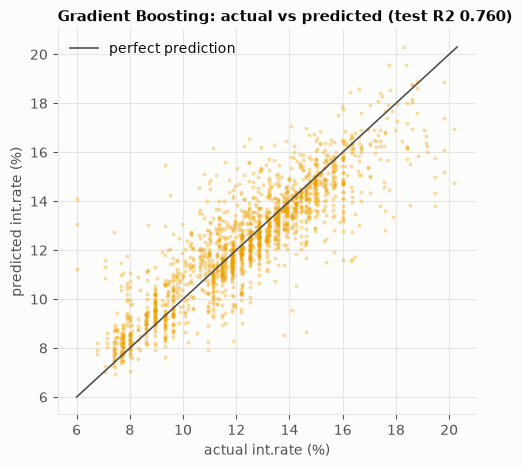

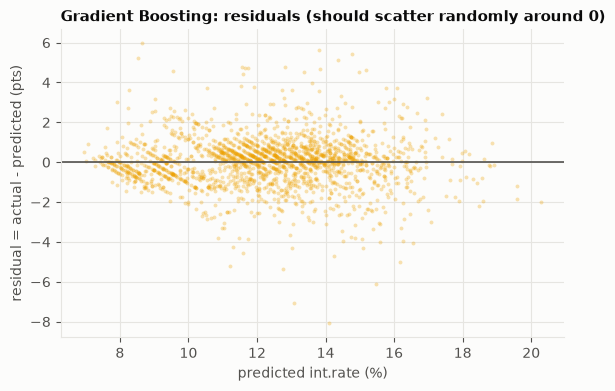

saved + reloaded TrainedModels/Regression/04_Gradient_Boosting_Regressor.joblib (identical predictions: True)


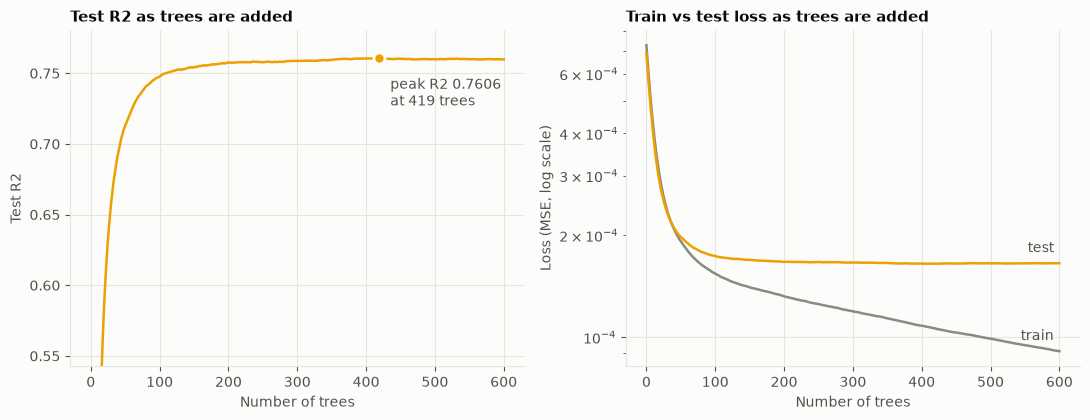


test R2 peaks at 0.7606 with 419 trees (of 600)


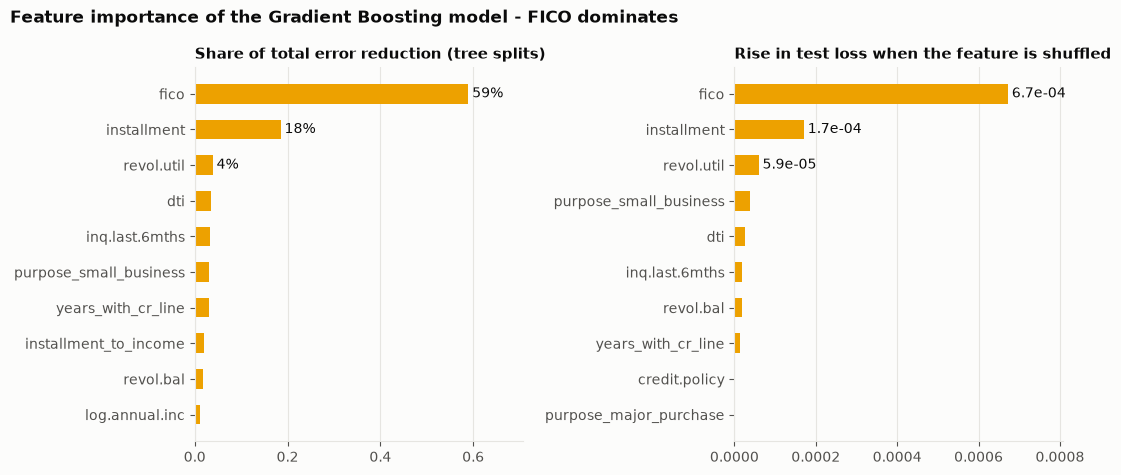


share of the total error reduction (top 8):
fico                      0.589207
installment               0.184913
revol.util                0.038399
dti                       0.034704
inq.last.6mths            0.033491
purpose_small_business    0.030797
years_with_cr_line        0.029846
installment_to_income     0.020101

example applicant (FICO 720, DTI 12.5, income $65k): predicted int.rate = 10.66%


In [3]:
# Results: metrics, loss curve, actual vs predicted, residuals, saved model
gb = model.model
row = report_regressor(
    out,
    "4. Gradient Boosting (better)",
    model,
    d,
    gb.train_loss,
    (sk_r2, "scikit-learn GradientBoostingRegressor (different random subsamples)"),
)

# performance curve: train / test error after every added tree
staged_test = [r2(d.y_test, p) for p in gb.staged_predict(d.X_test)]
train_mse = [mse(d.y_train, p) for p in gb.staged_predict(d.X_train)]
test_mse = [mse(d.y_test, p) for p in gb.staged_predict(d.X_test)]
pd.DataFrame(
    {"n_trees": range(len(staged_test)), "train_mse": train_mse, "test_mse": test_mse, "test_r2": staged_test}
).to_csv(out.table("performance_curve.csv"), index=False)
plots.plot_boosting_performance(
    np.arange(len(staged_test)), train_mse, test_mse, staged_test, out.image("performance_curve.png")
)
print(f"\ntest R2 peaks at {max(staged_test):.4f} with {int(np.argmax(staged_test))} trees (of {gbr['n_estimators']})")

# feature importance: share of the total error reduction, and the rise in test MSE when a feature is shuffled
gain = pd.Series(gb.feature_importances_, index=d.feature_cols).sort_values(ascending=False)
perm = pd.Series(permutation_importance(gb.predict, d.X_test, d.y_test), index=d.feature_cols).sort_values(
    ascending=False
)
pd.DataFrame({"gain_share": gain, "permutation_mse_rise": perm}).sort_values("gain_share", ascending=False).to_csv(
    out.table("feature_importance.csv"), index_label="feature"
)
plots.plot_feature_importance(gain, perm, out.image("feature_importance.png"))
print("\nshare of the total error reduction (top 8):")
print(gain.head(8).to_string())

# use the saved model: predict the rate of a new applicant
applicant = {
    "credit.policy": 1,
    "installment": 300.0,
    "log.annual.inc": np.log(65000),
    "dti": 12.5,
    "fico": 720,
    "revol.bal": 8000,
    "revol.util": 40.0,
    "inq.last.6mths": 1,
    "delinq.2yrs": 0,
    "pub.rec": 0,
    "installment_to_income": 300.0 / 65000,
    "high_revol_util": 0,
    "bad_history_flag": 0,
    "years_with_cr_line": 10.0,
}
x_new = np.array([[applicant.get(c, 0) for c in d.feature_cols]], dtype=float)
rate = float(model.predict(x_new)[0])
print(f"\nexample applicant (FICO 720, DTI 12.5, income $65k): predicted int.rate = {rate * 100:.2f}%")